## CellVADIS on the MASS cytometry atlas

This notebook shows how to apply CellVADIS to a mass cytometry panel from a tissue-trafficking atlas of human T cells. The data was originally published by Wong et al [https://doi.org/10.1016/j.immuni.2016.07.007](https://doi.org/10.1016/j.immuni.2016.07.007). With data available at flowrepository.org with Repository ID FR-FCM-ZZTM ([Link](http://flowrepository.org/id/FR-FCM-ZZTM))

The workflow is similar to the single-cell RNA-seq example, but here the input is a panel of mass-cytometry markers instead of computing distances on a latent PCA space.

The steps in this notebook are:
- load and merge the tissue-level FCS files,
- keep the migration and differentiation markers as defined by Wong et al. 
- z-score normalize each cell and define source / target tissue labels,
- run JointOT and StitchOT,
- visualize tissue transition proportions, identify tissue-specific trafficking signatures and check for potential homing niches


In [1]:
# Notebook setup for the MASS example.
# We import the data-loading and analysis libraries, then bring in CellVADIS.
import anndata as ad 
import numpy as np 
import pandas as pd 
import pytometry as pm

from pathlib import Path
from scipy.stats import zscore

%load_ext autoreload
%autoreload 2
import CellVADIS


/home/wickerlw/Projects/CellVADIS_test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Assemble the MASS dataset from multiple FCS files.
# This step keeps only the markers relevant for migration and differentiation and creates a single AnnData object.
path_data = "docs/data/MASS/CD4/"

keep_columns = ["CD29", "CD62L", "CLA", "CD103", "CCR4", "CD49a", "CCR10", "CXCR6",
                  "CCR9", "CXCR3", "CD31", "CXCR5",
                  "CD49d", "CCR2", "IntegrinB7", "CCR5", "CCR6", "CCR7", "CX3CR1", "CXCR4",
                  "CD69", "CD25", "CD45RO", "CD27", "ICOS", "PD-1", "CD161", "CD95", "CD45RA", "CD127"]

# Keep migration markers.
columns_order = ['CCR2', 'CCR4', 'CCR5', 'CCR6', 'CCR7', 'CCR9', 'CCR10', 'CD29', 'CD31', 'CD103', 'CD62L', 
                 'CD49a','CD49d', 'CLA', 'CXCR3', 'CXCR4', 'CXCR5', 'CXCR6', 'CX3CR1', 'IntegrinB7', ]
# Keep differentiation markers as defined in the original study.
columns_order_diff = ['CD25', 'CD27', 'CD45RA', 'CD45RO', 'CD69', 'CD95', 'CD127', 'CD161', 'ICOS', 'PD-1']
all_columns_order = columns_order + columns_order_diff

tissue_colors = {
    "Tonsil": "#0072B2",
    "Spleen": "#E69F00",
    "Colon": "#009E73",
    "Skin": "#fbafe4",
    "Lung": "#F0E442",
    "Liver": "mediumpurple"
}

adata_stack = []
files = [str(f) for f in Path(path_data).glob("*.fcs")]
# Exclude any file names that contain CB; these are not part of the analysis here.
files = [f for f in files if "CB" not in f]
sample_ids = [f.split('_')[1] for f in files]
for file, file_id in zip(files, sample_ids, strict=False):
    adata = pm.io.read_fcs(file)
    if file_id is not None:
        adata.obs["sample"] = file_id
    
    # Remove duplicate columns before filtering to the selected markers.
    duplicate_columns = [col for col in adata.var_names if list(adata.var_names).count(col) > 1]
    adata = adata[:, ~adata.var_names.isin(duplicate_columns)]
    # Keep only the markers that are relevant for this analysis.
    adata = adata[:, adata.var_names.isin(all_columns_order)]

    # Reorder columns to match the desired marker order for downstream consistency.
    adata = adata[:, [col for col in all_columns_order if col in adata.var_names]]
    adata_stack.append(adata)

adata = ad.concat(adata_stack, join="outer", uns_merge="unique", index_unique="-")

# Split the sample label into tissue and sample ID columns.
# The original FCS metadata is stored in a compact format such as TissueSampleID.
adata.obs[["location", "sample_id"]] = adata.obs["sample"].str.extract(r'([A-Za-z]+)(\d+)')
# Get the number of cells per tissue.
print(adata.obs["location"].value_counts())

# Normalize each cell on a row-wise z-score scale so that expression is comparable across markers.
adata.obsm["X_zscore"] = zscore(adata.X, axis=1)
adata.layers["X_zscore"] = adata.obsm["X_zscore"]

/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args

location
PBMC      175132
Tonsil    154107
Liver     115931
Skin       61641
Spleen     57479
Lung       33826
Colon      26974
Name: count, dtype: int64


## Apply CellVADIS

In [3]:
# Define the source and target tissue compartments for the MASS example.
# The blood compartment is treated as the source population and the remaining tissues are targets.
adata_OT = adata.copy()  # Keep a working copy for CellVADIS analysis so the original object remains intact.

# Define target names
target_names = ["Tonsil", "Spleen", "Colon", "Skin", "Lung", "Liver"]
# Make sure the color order matches the target order.
target_colors = [tissue_colors[tissue] for tissue in target_names]
# Define source name
source_name = 'PBMC'
# Subsampling is recommended before OT to reduce bias from large tissue-specific sample sizes.
adata_OT = CellVADIS.utils.obs_key_wise_subsampling(adata_OT, ["location"], N_target=1000, N_source=5000, source_name="PBMC", in_place=False)

print("Tissue counts after subsampling: ")
print(adata_OT.obs["location"].value_counts())
# Apply the OT methods to the z-scored marker matrix.
CellVADIS.JointOT(
    adata=adata_OT,
    obsm_key="X_zscore",
    source_name=source_name,
    target_names=target_names,
    store_in_adata=True,
    assign_unsampled_probs=False,
    output_key="jointOT"
) 

CellVADIS.StitchOT(
    adata=adata_OT,
    obsm_key="X_zscore",
    source_name=source_name,
    target_names=target_names,
    store_in_adata=True,
    tau_a=0.5,
    tau_b=0.995,
    assign_unsampled_probs=False,
    output_key="stitchOT"
)


Tissue counts after subsampling: 
location
PBMC      5000
Colon     1000
Liver     1000
Lung      1000
Skin      1000
Spleen    1000
Tonsil    1000
Name: count, dtype: int64


## 2. Analyse CellVADIS results

First we compute the proportions of source cells trafficking to specific targets. 
E.g. CellVADIS predicts that 9% of source cells will migrate to the tonsils. \
Note that without setting assign_unsampled_probs=True, this does not account for unobserved tissue sites.


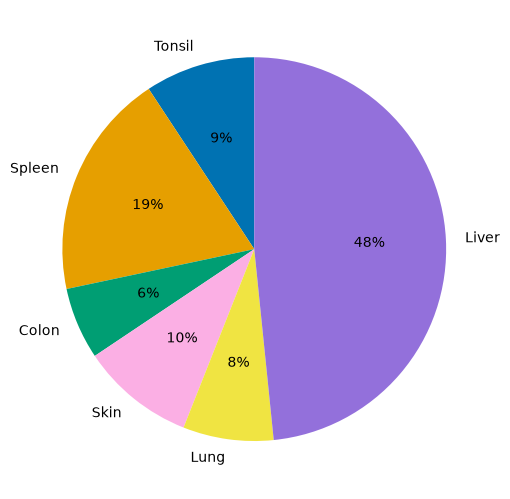

[0.09270822 0.19061313 0.06059299 0.09602172 0.07623883 0.48382511]


In [4]:
print(CellVADIS.plotting.plot_tissue_transition_proportions(adata_OT, 
                                                            output_key="stitchOT", return_proportions=True, colors=target_colors))

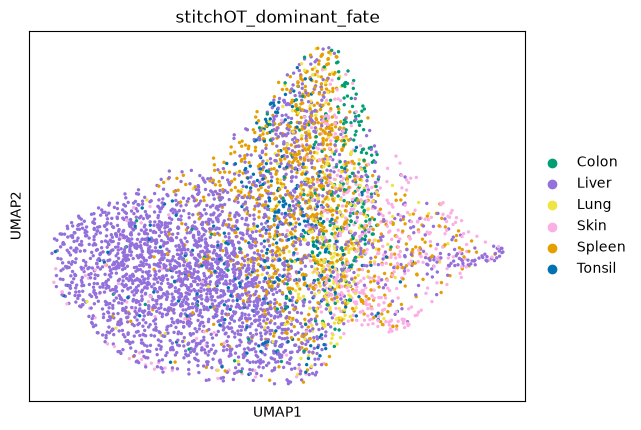

In [5]:
CellVADIS.plotting.plot_dominant_fates(adata_OT, output_key='stitchOT', colors=target_colors)

Instead of only coloring source cells by their most dominant fate, we can also plot the full fate probabilities for a subset of source cells:

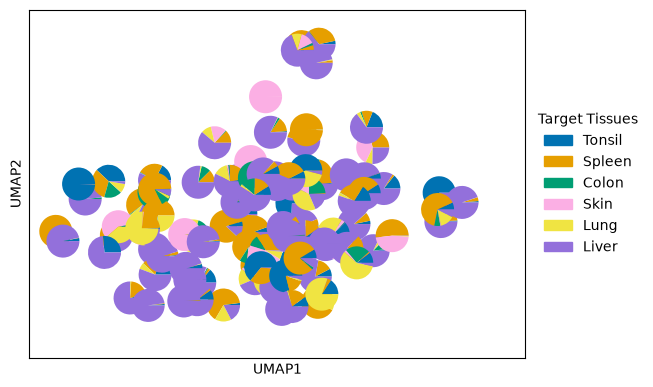

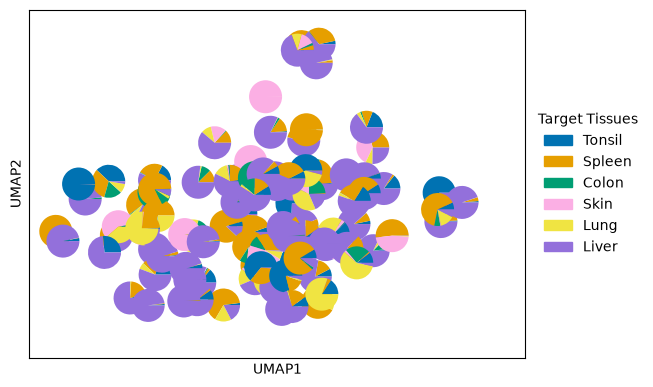

In [ ]:
CellVADIS.plotting.plot_fate_probabilities_with_pie_charts(
    adata_OT,
    colors=target_colors,
    output_key='stitchOT',
    s=250,
    show=True,
    return_fig=False,
)


### Trafficking signatures
We can also correlate fate probabilities as determined by our OT methods with the marker expressions on our source cells to determine trafficking signatures

In [7]:
fate_corr_df = CellVADIS.utils.corr_marker_with_fates(adata_OT, output_key="stitchOT", marker_genes=adata_OT.var_names,
                                       return_as_df=True, sort_df_by="mean")
print(fate_corr_df.head(10))

          Tonsil    Spleen     Colon      Skin      Lung     Liver
CXCR4   0.046403  0.357736  0.517126  0.307992  0.523928 -0.228648
CD62L   0.234338 -0.049688 -0.468839 -0.454052 -0.284625  0.386416
CD45RO -0.329751  0.219399  0.319807  0.521356  0.357398 -0.565488
CD95   -0.327462  0.210537  0.309416  0.516315  0.310206 -0.547935
CXCR3  -0.132791  0.146857  0.247144  0.199475  0.225890 -0.248294
CD127  -0.131683  0.081809  0.192189  0.063811  0.147988  0.035591
CD45RA  0.326097 -0.236467 -0.255753 -0.397181 -0.309152  0.548897
CXCR5   0.073948  0.051914  0.137034  0.031962  0.093673 -0.136748
CCR7    0.420032 -0.036880 -0.283686 -0.603386 -0.249112  0.502482
CD49d  -0.055376  0.056626  0.173619  0.019213  0.150738 -0.101547


### Homing niches

By computing a UMAP for each tissue seperately we can use the computed optimal transport plan to project source cells with a high fate probability towards this specific tissue (>1/3) into the UMAP space. This allows to identify potential tissue entry points, which could also guide the definition of initial cell populations for trajectory inference methods

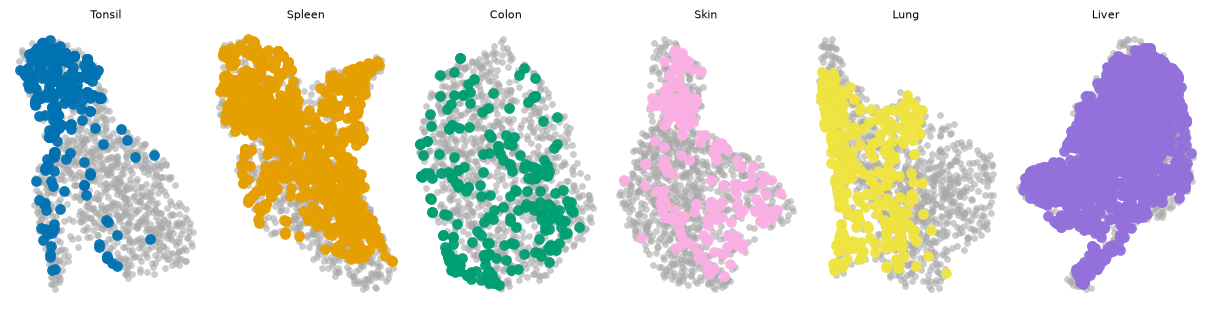

In [8]:
CellVADIS.plotting.plot_homing_niches(
    adata_OT,
    output_key='jointOT',
    colors=target_colors,
    figsize=(12, 3),
    show=True
)

In [9]:
CellVADIS.utils.corr_marker_with_target_marginals(
    adata_OT,
    marker_genes=adata_OT.var_names,
    return_as_df=True,
    #obsm_key='X_zscore',
    output_key="jointOT",
    sort_df_by="Tonsil"
)

,Tonsil,Spleen,Colon,Skin,Lung,Liver
PD-1,-0.781184,-0.488757,-0.236336,-0.208673,-0.133602,-0.227213
CD69,-0.718640,-0.590555,-0.395961,-0.532083,-0.587778,-0.064483
ICOS,-0.682224,-0.308254,-0.107197,0.038146,0.023444,0.042974
CCR7,0.670745,0.310349,0.379395,0.008760,0.521076,0.346105
CXCR5,-0.646902,-0.419912,0.098896,-0.062756,-0.242954,-0.097177
CD95,-0.622163,-0.216686,-0.086628,0.073840,0.052662,-0.276088
CD45RA,0.474493,0.165794,0.074055,-0.307544,0.232179,0.402275
CD62L,0.466424,0.383738,0.029888,0.062352,0.232478,0.356448
CD45RO,-0.419063,-0.207789,0.021162,0.214633,-0.198970,-0.303292
CX3CR1,0.371841,0.099070,0.060900,0.020189,0.361710,0.143676


## We can also rerun CellVADIS to account for unobserved tissues

In [10]:
CellVADIS.StitchOT(
    adata=adata_OT,
    obsm_key="X_zscore",
    source_name=source_name,
    target_names=target_names,
    store_in_adata=True,
    tau_a=0.5,
    tau_b=0.995,
    assign_unsampled_probs=True,
    output_key="stitchOT_with_unsampled"
)

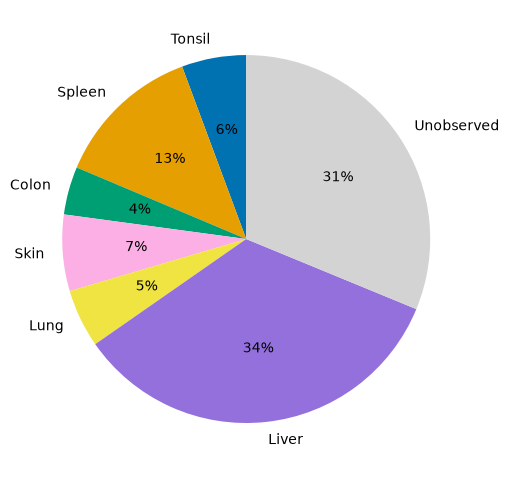

In [11]:
CellVADIS.plotting.plot_tissue_transition_proportions(adata_OT, 
                                                            output_key="stitchOT_with_unsampled", return_proportions=False, colors=target_colors + ["lightgray"])

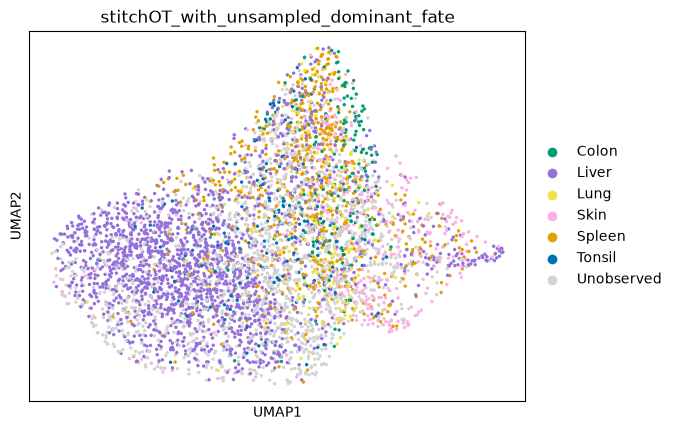

In [12]:
fig = CellVADIS.plotting.plot_dominant_fates(adata_OT, output_key="stitchOT_with_unsampled", colors=target_colors + ["lightgray"])

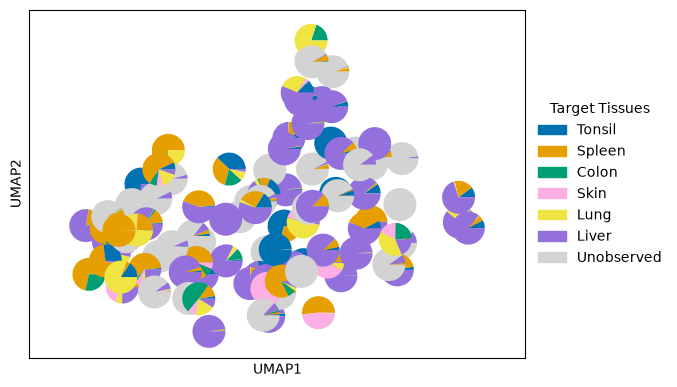

In [13]:
fig = CellVADIS.plotting.plot_fate_probabilities_with_pie_charts(
    adata_OT,
    colors=target_colors + ["lightgray"],
    output_key="stitchOT_with_unsampled",
    s=250,
    show=True,
    return_fig=True,
)

In [14]:
fate_corr_df = CellVADIS.utils.corr_marker_with_fates(adata_OT, output_key="stitchOT_with_unsampled", marker_genes=adata_OT.var_names,
                                       return_as_df=True)
fate_corr_df.head(10)

,Tonsil,Spleen,Colon,Skin,Lung,Liver,Unobserved
CXCR4,0.123511,0.383402,0.563301,0.372324,0.558952,-0.051195,-0.146662
CD62L,0.244874,-0.050779,-0.445313,-0.454505,-0.247175,0.328573,-0.006467
CD127,-0.046883,0.124030,0.212799,0.093037,0.186558,0.126865,-0.119245
CD45RO,-0.353070,0.145998,0.293316,0.504030,0.294619,-0.476627,0.028137
CD95,-0.335734,0.154711,0.291226,0.502277,0.266970,-0.457277,-0.001294
CXCR3,-0.133766,0.099828,0.231651,0.206408,0.197522,-0.198048,0.005386
CD49d,-0.035253,0.055841,0.164303,0.036867,0.146739,-0.056717,-0.038189
CCR2,-0.155776,0.008304,0.171074,0.177695,0.128516,-0.085708,-0.016748
CD161,0.036324,-0.075043,-0.017078,-0.182471,-0.051169,0.066691,0.001734
CD49a,-0.151297,0.041020,0.112993,0.220549,0.132100,-0.148371,0.001822
